# MSc in Molecular Biomedicine

## 1. Introduction: Basic Concepts in Statistics and Informatics for Bioscience

### Christoforos Nikolaou

#### Computational Genomics Group, BSRC "Alexander Fleming"

[computational-genomics.weebly.com](http://computational-genomics.weebly.com)

---

## Basic Concepts in Statistics and Informatics for Bioscience

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/CG2Webpage.png?raw=true)

Christoforos Nikolaou
Computational Genomics Group, BSRC "Alexander Fleming"
computational-genomics.weebly.com

---

## Introduction

* Why bioinformatics?
* Problems of Bioinformatics
* Remembering stuff (from as back as high-school)

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure00_02.jpg?raw=true)

---

## Goals

![](https://d32ogoqmya1dw8.cloudfront.net/images/NICHE/source_xkcd.com_1340307061.com_744.jpg)

* To remember some basic notions regarding math and statistics
* To understand why statistical reasoning is so important in every aspect of research
* To consider some simple (but not trivial) questions of data analysis

---

## Part A. Remembering stuff

---

## Which tools do we need to perform bioinformatics analyses?

* Algorithm design [simpler than what you may think]
* Computer skills [can be outsourced]
* Quantitative thinking and Statistics
* Quantitative thinking
* Reasoning with numbers
* Considering background models
* Plan quantitative controls

---

## Statistics

Provides tools for all of the above

---

## "Hot hands" in basketball (and the casino)

Problem #1: We tend to see patterns where they don't exist.

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/Statistics/hothands.png?raw=true)

_Can you discover "runs" of Xs or -s in the above panel?_


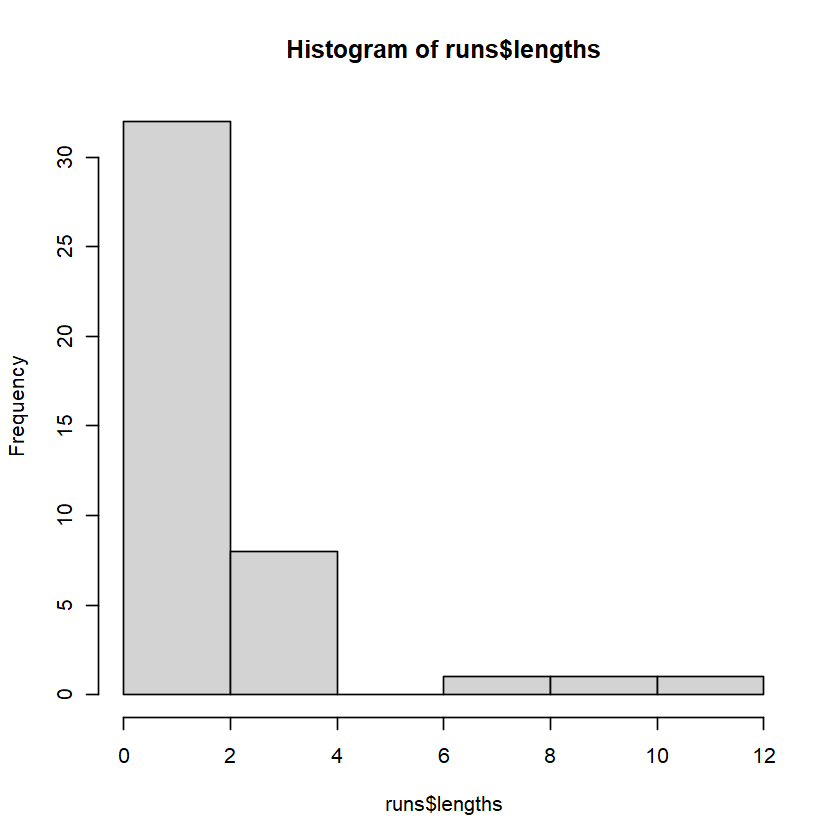

In [9]:
series <- rbinom(100, 1, 0.5)
runs <- rle(series)
hist(runs$lengths)



## A numbers game (guess a range!)

Try this simple game:

[Click here](https://how-confident-should-you-be.netlify.app/)

---

## A numbers game (guessing a range)

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/Statistics/Guesstimates_vs_Reality.png?raw=true)

Problem #2: We tend to be overconfident

---

## The case of the Sacked football managers

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/Statistics/premier-league-regression.jpg?raw=true)

* Distinguishing random fluctuations from real effects can be hard
* Problem #3: We are fooled by regression to the mean.




                     group    n mean_visit1 mean_visit2    change
1                 Everyone 5000         120         120  -0.00473
2 Selected (visit1 >= 140)  297         146         135 -10.79810



	Paired t-test

data:  visit2 and visit1
t = -18.088, df = 296, p-value < 2.2e-16
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -11.97297  -9.62322
sample estimates:
mean difference 
       -10.7981 



Reliability (theoretical r): 0.61 
Observed cor(visit1, visit2): 0.62 
Predicted mean visit2 for selected: 135.6 
Observed mean visit2 for selected: 134.8 


`geom_smooth()` using formula = 'y ~ x'


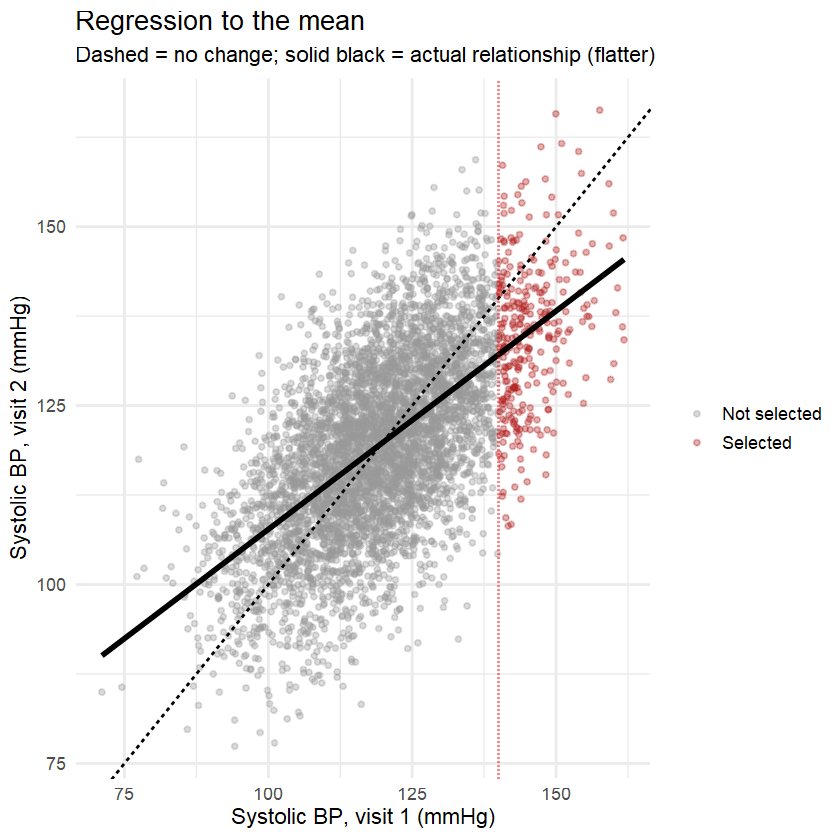


Selected LOW at visit 1: mean visit1 = 94.6 -> mean visit2 = 103.6 


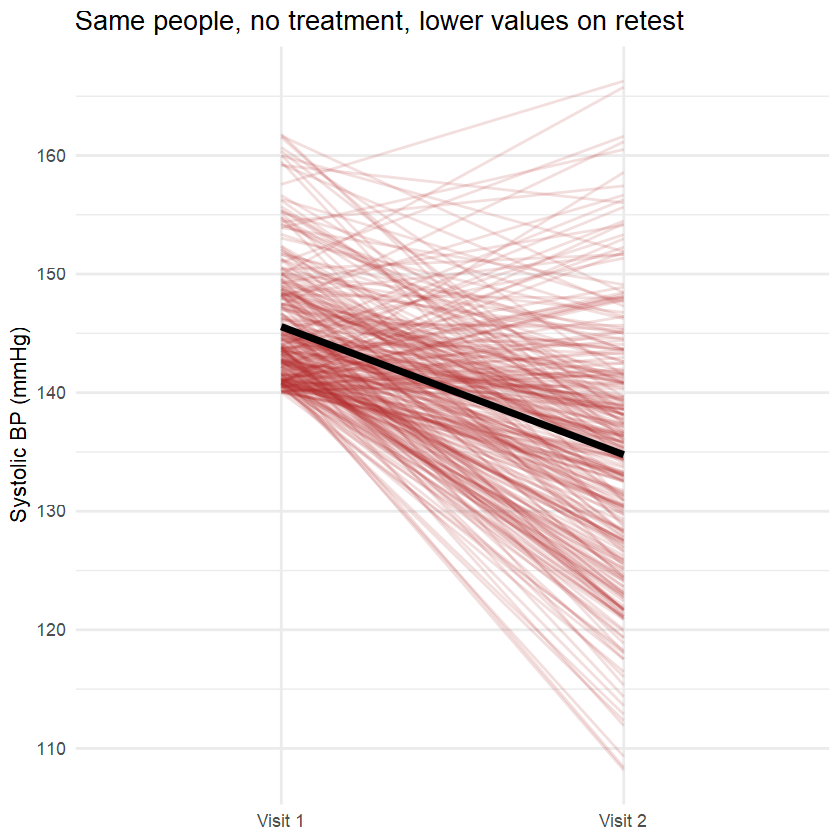

In [12]:
library(ggplot2)
set.seed(42)

# ---- 1. Simulate a population ------------------------------------------
n        <- 5000
true_sbp <- rnorm(n, mean = 120, sd = 10)   # stable between-person differences
noise_sd <- 8                               # day-to-day / measurement variability

visit1 <- true_sbp + rnorm(n, 0, noise_sd)  # screening visit
visit2 <- true_sbp + rnorm(n, 0, noise_sd)  # follow-up, NO intervention

d <- data.frame(visit1, visit2)

# ---- 2. Select the "hypertensive" at screening --------------------------
d$selected <- d$visit1 >= 140

summary_tbl <- data.frame(
  group       = c("Everyone", "Selected (visit1 >= 140)"),
  n           = c(nrow(d), sum(d$selected)),
  mean_visit1 = c(mean(d$visit1), mean(d$visit1[d$selected])),
  mean_visit2 = c(mean(d$visit2), mean(d$visit2[d$selected]))
)
summary_tbl$change <- summary_tbl$mean_visit2 - summary_tbl$mean_visit1
print(summary_tbl, digits = 3)

# Paired test on the selected group: a "significant drop" with no treatment!
with(d[d$selected, ], t.test(visit2, visit1, paired = TRUE))

# ---- 3. The theory: expected visit2 = mu + r * (visit1 - mu) -----------
r_theory <- var(true_sbp) / (var(true_sbp) + noise_sd^2)   # reliability
cat("\nReliability (theoretical r):", round(r_theory, 2),
    "\nObserved cor(visit1, visit2):", round(cor(d$visit1, d$visit2), 2), "\n")

mu <- mean(d$visit1)
cat("Predicted mean visit2 for selected:",
    round(mu + r_theory * (mean(d$visit1[d$selected]) - mu), 1),
    "\nObserved mean visit2 for selected:",
    round(mean(d$visit2[d$selected]), 1), "\n")

# ---- 4. Plot 1: the scatter shows the slope is < 1 ----------------------
ggplot(d, aes(visit1, visit2, colour = selected)) +
  geom_point(alpha = 0.35, size = 1) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +       # "no change"
  geom_smooth(aes(group = 1), method = "lm", colour = "black", se = FALSE) +
  geom_vline(xintercept = 140, colour = "red", linetype = "dotted") +
  scale_colour_manual(values = c("grey60", "firebrick"),
                      labels = c("Not selected", "Selected")) +
  labs(title = "Regression to the mean",
       subtitle = "Dashed = no change; solid black = actual relationship (flatter)",
       x = "Systolic BP, visit 1 (mmHg)", y = "Systolic BP, visit 2 (mmHg)",
       colour = NULL) +
  theme_minimal(base_size = 13)

# ---- 5. Plot 2: paired view of the selected individuals -----------------
sel <- d[d$selected, ]
sel$id <- seq_len(nrow(sel))
long <- rbind(data.frame(id = sel$id, visit = "Visit 1", sbp = sel$visit1),
              data.frame(id = sel$id, visit = "Visit 2", sbp = sel$visit2))

ggplot(long, aes(visit, sbp, group = id)) +
  geom_line(alpha = 0.15, colour = "firebrick") +
  stat_summary(aes(group = 1), fun = mean, geom = "line",
               colour = "black", linewidth = 1.5) +
  labs(title = "Same people, no treatment, lower values on retest",
       x = NULL, y = "Systolic BP (mmHg)") +
  theme_minimal(base_size = 13)

# ---- 6. Bonus: the opposite selection shows it works in both directions -
low <- d$visit1 <= 100
cat("\nSelected LOW at visit 1: mean visit1 =", round(mean(d$visit1[low]), 1),
    "-> mean visit2 =", round(mean(d$visit2[low]), 1), "\n")


### Deductive Reasoning 

https://en.wikipedia.org/wiki/Wason_selection_task

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/General/DeductiveReasoning.png?raw=true)

---



## The Texas sharpshooter's fallacy

![](https://www.bayesianspectacles.org/wp-content/uploads/2018/01/TexasSharpShooter.png)

* Drawing the target around your hit
* Picking your hypothesis **first**
* Considering multiple p-values

---

## Are anorexic women born in June?

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/Statistics/AnorexicWomenJune.png?raw=true)

---

## Are anorexic women born in June?

* 446 women born over a 30-year period, diagnosed with anorexia nervosa.
* Mean number of births per month over the 30-year period was 37.
* 48 of the patients born in June (p-value=0.0427)
* Conclusion: It's more likely to develop anorexia nervosa if you are born in June

---

## What is the problem?

* Asking the wrong question:
* June is just one of the 12 months. What is the probability of **any month** having 48 or more births? It is p=0.47.
* Getting one low p-value after **having calculated many p-values** doesn't make that one any special

---




## A lot of p-values

![](https://i.stack.imgur.com/zKaSX.png)

* I give a coin to one of you and ask you to flip it ten times. If you bring 9 heads how would you describe the coin?
* I give the same coin to each one and ask you to flip it ten times. If one of you gets 9 heads what he/she should tell me about the coin?

---

## Should we be scared of mamograms?

* A mamogram is **correctly positive** 90% of times. It's falsely positive 7% of the times.
* A 40-year old woman gets a positive mamogram test.
* What are the chances she **actually** has breast cancer?

_Think before you answer_

---




## Priors, Posteriors and Conditional probabilities

* _Being positive given you have cancer_ is 90%
* But _having cancer given your are positive_ __is not the same!__
* The actual probability depends on **how many 40-year old women get breast cancer**

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/Statistics/BayesRule.jpeg?raw=true)

---

## Bayes Theorem

## ![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/Statistics/BayesTheorem.jpg?raw=true)



In [14]:
library(ggplot2)

bayes_ppv <- function(prev, sens, spec) {
  (sens * prev) / (sens * prev + (1 - spec) * (1 - prev))
}

prev <- 0.01   # prior: P(disease)
sens <- 0.95   # P(+ | disease)
spec <- 0.95   # P(- | no disease)

bayes_ppv(prev, sens, spec)

set.seed(1)
n <- 1e5
disease  <- rbinom(n, 1, prev)
test_pos <- ifelse(disease == 1,
                   rbinom(n, 1, sens),       # true positives
                   rbinom(n, 1, 1 - spec))   # false positives

table(Disease = disease, Test = test_pos)

mean(disease[test_pos == 1])   # empirical P(disease | positive) ≈ 0.16

[1] 0.1610169

       Test
Disease     0     1
      0 93968  4992
      1    59   981

[1] 0.1642391

Among about **1,000 diseased people**, roughly 950 test positive. Among about 99,000 healthy people, roughly 4,950 also test positive. The healthy group is so much larger that false positives swamp true positives.

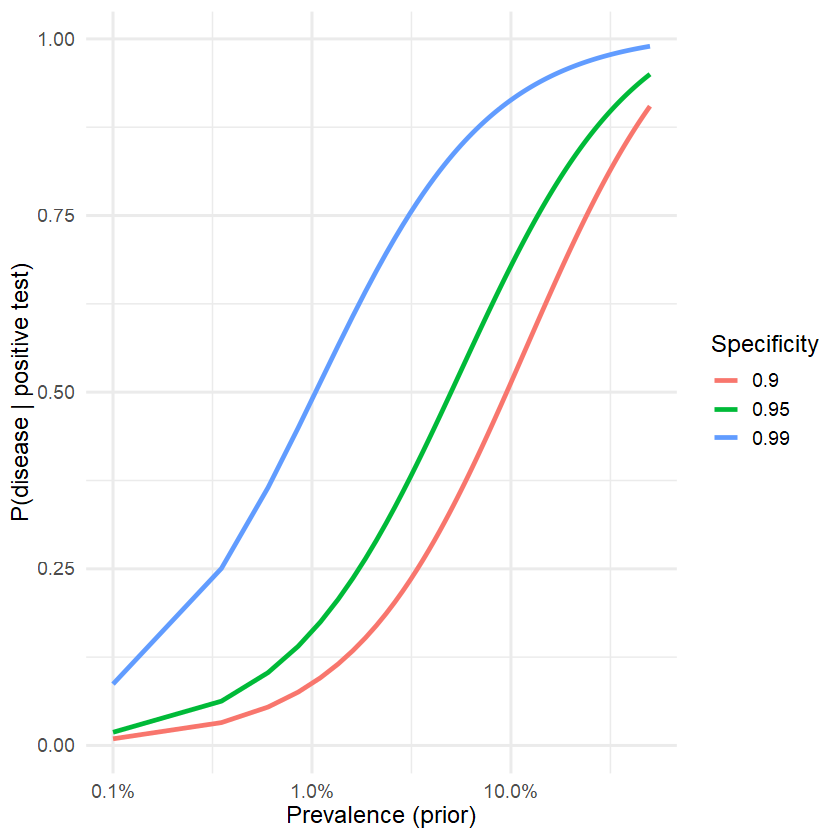

In [15]:
grid <- expand.grid(prev = seq(0.001, 0.5, length.out = 200),
                    spec = c(0.90, 0.95, 0.99))
grid$ppv <- bayes_ppv(grid$prev, sens = 0.95, grid$spec)

ggplot(grid, aes(prev, ppv, colour = factor(spec))) +
  geom_line(linewidth = 1) +
  scale_x_log10(labels = scales::percent) +
  labs(x = "Prevalence (prior)", y = "P(disease | positive test)",
       colour = "Specificity") +
  theme_minimal(base_size = 14)

## Part B. Planning your analyses

---

## How to plan your analyses

* Starting Point: Studied phenomenon -> hypothesis, question
* Experiment. What will the readout be? -> technique
* Measurement. How will we measure it? -> Quantification
* Data analysis -> Interpretation
* End point: Understanding phenomenon. New knowledge.

---

## Some easy questions (Data Structure)

1. What is the type of your outcome? Are you reporting a binomial (YES/NO) effect or is your outcome continuous values of a physical property?
2. Which are your explanatory variables? Are they categorical (e.g. "wild-type vs. treated") or continuous (e.g. dosage of a drug)?

---

## Some easy questions (Comparisons)

3. How many conditions are you analyzing? Is it one, two or more?
   If you are comparing more than one conditions are your data matched? Do they come in pairs or not?

---

## Some easy questions (Types of Outcome)

Types of outcome

* binomial (yes/no, dead/alive, improved/not)
* continuous (temperature, fluoresence, weight etc)
* parametrical ("blue","green","red")
* How can you describe the above in numbers? When will you use values, frequencies, ratios?
* If your outcome is continuous is it normally distributed? Do you even know what "normally distributed" is?

---

## Some easy questions (Explanatory variables)

* Can the objects you measure be categorized?
* If yes, in how many groups?
* If not, what is the variable that could be used to define them (age, treatment, genetic background)

_Try to describe experiments for each type_

---

## Some easy questions (Number of conditions)

* One condition: You can only ask if two or more outcomes are associated
* Two conditions: You can compare the same outcome between the two conditions
* More than two conditions: You can compare between two or more conditions but you are doing multiple comparisons

---

## Some easy questions (Types of Comparisons)

* Matched or unmatched samples
* Samples are unmatched. You can compare their means but you cannot ask for correlations or "congenital" differences
* Samples are matched. You can also track paired differences

---

## Some easy questions (Normality)

* Is it Normal or is it not?
* What can we do when our data are normally distributed?
* A number of tests apply, such as Student's t-test to compare means,ANOVA to analyze variance etc
* More importantly. What can we do when they aren't?

   1. try to transform the data
   2. apply non-parametric tests
   3. KEY solution: apply computational tests

---

## Part C. Some practical questions

---

## Practical Question #1

We are administering a treatment to a set of patients in the form of a substance and we want to see if the efficiency of the treament is dependent on the genetic background.

_How should we plan our experiment?
What should we measure?
What should we be careful of?_

---

## Practical Question #2

We want to test the effect of a drug between two sets of patients. One set is taking the drug, the other is taking a placebo. We measure the weight gain of the patients before and after administration.
What is the type of the outcome?
Which is the explanatory variable?
What is the question we should ask?

_What test should we use?
What should we be careful of?_

---

## Practical Question #3

We are feeding a set of mice with an assumed "superfood" at different doses.
We want to see if this has any effect on their susceptibility to cancer.
We expose the mice to X-ray radiation and measure tumour occurrence.
How can we tell if the superfood is effective?

_Can we measure how effective it is?_
_How will we control our experiment?_

---

## Part C. Bioinformatics

---

## Bioinformatics

![](https://www.fiosgenomics.com/wp-content/uploads/2019/07/Bioinformatics-Position-Thumbnail.png)

* A piece of software
* A series of analyses performed by a technician/intern/geek to make your experiments look fancier
* Many things in your or other people's papers that you don't understand :)

---

## What Bioinformatics actually is

Any computational approach to answer or pose a biological question
including:

* New algorithms (not yet implemented)
* Software implementation (web services etc)
* Data interpretation through computation
* Predictive or explanatory models

---

## What we need Bioinformatics for

1. Consider measuring the expression of one gene between two conditions. Then consider doing the same for all genes in a genome between more than one conditions. [Handling of big data]

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure07_05.jpg?raw=true)

---

## What we need Bioinformatics for

2. Think of ways to identify regulatory sequences in a genome. Then try to think how you would decide which ones are more likely to have a strong effect in the activation of some gene of interest. [Resolving Complexity]

![](https://media.springernature.com/m685/springer-static/image/art%3A10.1038%2Fnbt0406-423/MediaObjects/41587_2006_Article_BFnbt0406423_Fig1_HTML.gif)

---

## What we need Bioinformatics for

1. You have identified a geneis over-expressed among patients suffering from a certain condition. Now can you use it to predict if a given individual who is genotyped will have the condition? [Modeling a system]

![](https://www.ebi.ac.uk/training/online/courses/gwas-catalogue-exploring-snp-trait-associations/wp-content/uploads/sites/26/2020/05/commercial-snp-arrays.png)

---

## A few (easy?) questions

1. How much more is a gene expressed between two conditions?
2. Is the human or the yeast genome richer in genes?
3. Which human chromosome is more important for the function of mitosis?

_Think of the information you will need to answer these questions before you go about answering them._

---

## And a few not so easy ones

1. How can I locate a given sequence on a genome?
2. How can I say which is the DNA-binding motif of protein?
3. Which of the conditions of my experiment are more similar to each other?
4. How can the expression of genes A,B,C etc be predicted?
5. Which of all the genes that came out of my experiment should I focus on?

---

## Problems of Bioinformatics #1

![](https://media.springernature.com/m685/springer-static/image/art%3A10.1038%2Fnbt0209-153/MediaObjects/41587_2009_Article_BFnbt0209153_Fig1_HTML.gif)

Transcriptional Complexity. How complex is a gene?
the Question: What can we know about the region in which the gene resides?

---

## Problems of Bioinformatics #2

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure00_02.jpg?raw=true)

Genome Architecture. How are genes distributed in the genome?
the Question: Which underlying features are correlated with their distribution?

---

## Problems of Bioinformatics #3

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure00_03.jpg?raw=true)

Sequence similarity/homology
the Question: How can we locate a "string" of DNA in a genome?

---

## Problems of Bioinformatics #4

Analyzing Gene Regulation
the Question: Where does a transcription factor bind on the genome?

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure03_07.jpg?raw=true)

---

## Problems of Bioinformatics #5

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure00_05.jpg?raw=true)

Gene Expression Analysis. How is gene regulation orchestrated in different conditions?
the Question: Which group of genes changes expression in time during a development?

---

## Problems of Bioinformatics #6

![](https://apps.cytoscape.org/media/cluego/screenshots/ClueGO_fig4_2.png)

Functional Analysis of Gene Expression
the Question: Which biological functions/pathways are more important given a set of over/under-expressed genes?

---

## Problems of Bioinformatics #7

![](https://github.com/christoforos-nikolaou/MolBioMedClass/blob/master/Figures/CompBio/Figure09_01.jpg?raw=true)

Biological Networks
What can we learn from the association of biological entities?
the Question: Which protein(s) are most important in a specific experimental context?

---

## Problems of Bioinformatics #8

![](https://www.ebi.ac.uk/training/online/courses/gwas-catalogue-exploring-snp-trait-associations/wp-content/uploads/sites/26/2020/05/commercial-snp-arrays.png)

Genomic Variation. How can we link genetic variability with the phenotype?
the Question: How can we locate gene polymorphisms that are predictors of disease susceptibility?

---

## Problems of Bioinformatics #9

![](https://miro.medium.com/max/1200/1*N1-K-A43_98pYZ27fnupDA.jpeg)

Model design

The Question: Can we predict gene expression levels from other sources of data?

---

## Some useful Resources

* [Nature Biotechnology Primers](https://www.nature.com/nbt/articles?searchType=journalSearch&sort=PubDate&type=primer&page=1). A very interesting series of short, introductory descriptions of some useful (and some quite hardcore) bioinformatics concepts.
* [Nature Methods. Points of Significance](https://www.nature.com/collections/qghhqm/pointsofsignificance). A key primer series for statistics
* [Statistics in Biology](https://www.nature.com/collections/qghhqm). A few Nature Editorials on quantitative concepts for biologists.